# Day 46 — Deep Learning: One Neuron and the Perceptron

**Instructor:** Srinivasa Sai Chava · **Audience:** first-year undergraduates  
**Lesson:** 90 minutes concepts and live coding, then 30 minutes practice.  
**Prerequisites:** Python functions, lists, basic classification. Runs in Google Colab with NumPy and Matplotlib.

**Today:** identify input, weight, bias, weighted sum and activation; compute predictions; see why one straight boundary cannot solve XOR. **Next lesson:** learning updates and hidden layers.

A perceptron here means a neuron using a hard step activation. A network containing many such units is a separate idea.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def step(z):
    """Our Day 46 convention: 1 at or above zero, else 0."""
    return int(z >= 0)

def perceptron(x, w, b):
    z = float(np.dot(x, w) + b)
    return z, step(z)

w = np.array([0.8, 0.6])
b = -1.0
print('Ready. weights:', w, 'bias:', b)

Ready. weights: [0.8 0.6] bias: -1.0


## 1. We already know the question (10 min)

A classification model maps a row of input features to a label. In this small classroom example, `x1 = 1` means the deadline is soon and `x2 = 1` means unfinished work. We want `1` for a reminder. The chosen settings are **illustrative**, not learned from data.

In [11]:
rows = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
for x in rows:
    print(f'deadline={x[0]}, unfinished={x[1]}')

deadline=0, unfinished=0
deadline=0, unfinished=1
deadline=1, unfinished=0
deadline=1, unfinished=1


## 2. Anatomy of one artificial neuron (15 min)

```
x1 --(w1)--\
             [sum + bias] --(step)--> output
x2 --(w2)--/
```

1. **Inputs** `x1`, `x2`: numbers in a data row.
2. **Weights** `w1`, `w2`: multiply the matching inputs; negative weights can push down.
3. **Bias** `b`: a constant added even if both inputs are zero.
4. **Weighted sum** `z = w1*x1 + w2*x2 + b`.
5. **Activation**: our step function produces 1 when `z >= 0`, otherwise 0.

A biological neuron is only a useful analogy; this code is a mathematical model.

In [12]:
x = np.array([1, 1])
contributions = x * w
z, prediction = perceptron(x, w, b)
print('contributions:', contributions)
print('sum before bias:', contributions.sum())
print('sum after bias z:', z)
print('prediction:', prediction)
assert np.isclose(z, 0.4) and prediction == 1

contributions: [0.8 0.6]
sum before bias: 1.4
sum after bias z: 0.3999999999999999
prediction: 1


**Pause and predict:** what changes if the student has `x = [1, 0]`? Compute it on paper before running the next cell.

In [13]:
for x in rows:
    z, yhat = perceptron(x, w, b)
    print(f'x={x.tolist()}  z={z:+.1f}  output={yhat}')
assert [perceptron(x,w,b)[1] for x in rows] == [0,0,0,1]

x=[0, 0]  z=-1.0  output=0
x=[0, 1]  z=-0.4  output=0
x=[1, 0]  z=-0.2  output=0
x=[1, 1]  z=+0.4  output=1


## 3. How the activation switches (15 min)

A *hard* step outputs only 0 or 1. The boundary `z = 0` is included on the 1 side in our convention. Try `z = -0.01`, `0`, `+0.01`.

z=-1.00 -> 0
z=-0.01 -> 0
z= 0.00 -> 1
z= 0.01 -> 1
z= 1.00 -> 1


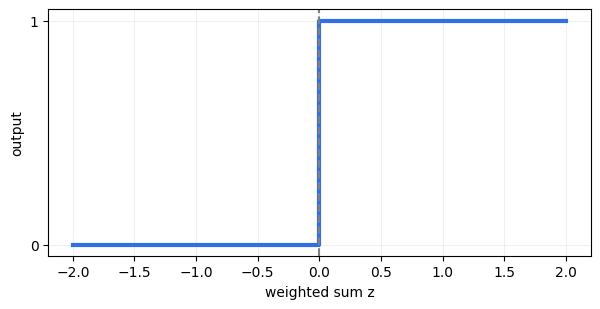

In [14]:
for z in [-1, -0.01, 0, 0.01, 1]:
    print(f'z={z:5.2f} -> {step(z)}')
z_values = np.linspace(-2, 2, 401)
plt.figure(figsize=(7, 3.2))
plt.step(z_values, [step(z) for z in z_values], where='post', color='#306FE8', linewidth=3)
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel('weighted sum z'); plt.ylabel('output'); plt.yticks([0, 1]); plt.grid(alpha=.2); plt.show()

## 4. The bias moves the switch (15 min)

We keep weights fixed and change only the bias. Compare the four possible input rows. A positive score is not a probability: this classic perceptron only makes a hard decision.

In [15]:
for trial_b in [-1.6, -1.0, -0.4, 0.1]:
    predictions = [perceptron(x, w, trial_b)[1] for x in rows]
    print(f'bias {trial_b:+.1f}: {predictions}')

bias -1.6: [0, 0, 0, 0]
bias -1.0: [0, 0, 0, 1]
bias -0.4: [0, 1, 1, 1]
bias +0.1: [1, 1, 1, 1]


## 5. One neuron makes a straight boundary (20 min)

For continuous inputs, all points with `w1*x1 + w2*x2 + b = 0` lie on a line. The two sides get opposite labels. **Class exercise:** where does this line cross the x1 axis when x2=0? Solve `0.8*x1 - 1 = 0`, so x1 = 1.25.

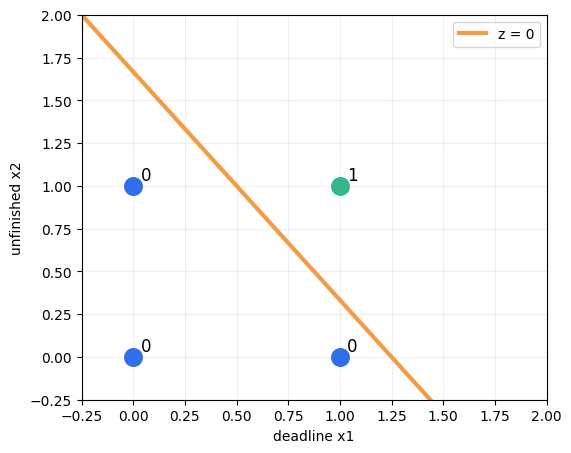

In [16]:
grid = np.linspace(-.25, 2, 200)
boundary_x2 = -(w[0] * grid + b) / w[1]
plt.figure(figsize=(6, 5))
plt.plot(grid, boundary_x2, color='#F49B45', linewidth=3, label='z = 0')
for x in rows:
    _, yhat = perceptron(x, w, b)
    plt.scatter(x[0], x[1], s=160, color=('#34B78A' if yhat else '#306FE8'), zorder=3)
    plt.text(x[0]+.035, x[1]+.035, str(yhat), fontsize=12)
plt.xlim(-.25, 2); plt.ylim(-.25, 2); plt.xlabel('deadline x1'); plt.ylabel('unfinished x2')
plt.legend(); plt.grid(alpha=.2); plt.show()

## 6. Why do we need networks? (15 min)

**XOR** is 1 when exactly one of two inputs is 1. Its positive corners are diagonally opposite. No single straight line separates both positive corners from both negative corners. Sketch it and try. A hidden layer combines more than one line, which we will study next session. This limitation applies to a *single* hard-step unit, not neural networks in general.

[0, 0] -> XOR label 0
[0, 1] -> XOR label 1
[1, 0] -> XOR label 1
[1, 1] -> XOR label 0


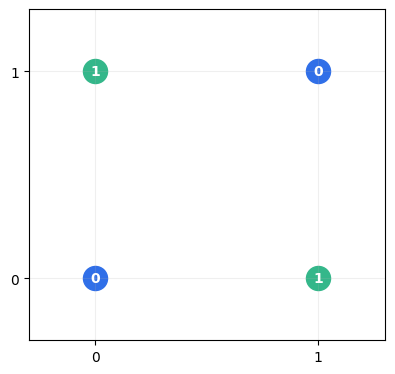

In [17]:
xor = np.array([0, 1, 1, 0])
for x, target in zip(rows, xor):
    print(f'{x.tolist()} -> XOR label {target}')
plt.figure(figsize=(4.6, 4.3))
for x, target in zip(rows, xor):
    plt.scatter(x[0], x[1], s=300, color='#34B78A' if target else '#306FE8')
    plt.text(x[0], x[1], str(target), ha='center', va='center', color='white', weight='bold')
plt.xlim(-.3,1.3); plt.ylim(-.3,1.3); plt.xticks([0,1]);plt.yticks([0,1]);plt.grid(alpha=.2);plt.show()

## 7. Connect the ideas (end-of-class recap)

- A neuron computes `z = sum(inputs × weights) + bias`, then transforms `z` using an activation.
- A perceptron uses a hard step to make a binary decision.
- We selected weights by hand today. Training adjusts them using examples.
- One perceptron draws one straight boundary; multiple layers can express richer patterns.

**Exit ticket:** For `x=[0,1]`, `w=[0.8,0.6]`, `b=-1`, show `z=-0.4` and output `0`. Explain the bias in one sentence.

Open the practice notebook for the 30-minute set. Solutions are a separate instructor file.